# Synthetic ECG generation (adapted SSSD-ECG)

Week 4 only. Week 3 CNN-LSTM stays frozen. Generator trains on `X_train` / `y_train` only.

**Chosen generator:** SSSD-ECG (https://github.com/AI4HealthUOL/SSSD-ECG), trained from scratch.

**Adaptations:** 4-class one-hot instead of 71 SCP codes; 8 independent leads I, II, V1–V6 then Einthoven reconstruction to the Week 2 12-lead order. No pretrained weights.


## 1. Environment check


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})

print("python", sys.version.split()[0])
print("torch", torch.__version__)
print("cuda", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is False. Do not run SSSD training on CPU. "
        "Need a CUDA PyTorch build (this machine has an RTX 3050)."
    )
print("gpu", torch.cuda.get_device_name(0))
print("vram_gb", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


python 3.14.2
torch 2.11.0+cu128
cuda True
gpu NVIDIA GeForce RTX 3050 Laptop GPU
vram_gb 4.0


## 2. Load training data


In [2]:
from synthetic_generation.config import (
    CLASS_ORDER, DATA_DIR, DIFFUSION_CONFIG, GENERATOR_NAME, GENERATOR_SOURCE,
    OUT_DIR, PILOT_SAMPLES_PER_CLASS, ROOT, SEED, TRAIN_FULL, TRAIN_PILOT,
    WAVENET_4GB, WAVENET_CONFIG,
)
from synthetic_generation.data import class_counts, load_train, one_hot
from synthetic_generation.leads import (
    INDEPENDENT_IDX, INDEPENDENT_LEADS, LEAD_ORDER_12, reconstruct_12, to_independent_8,
)
from synthetic_generation.sample import basic_sanity, generate_class_batch, metadata_rows
from synthetic_generation.train import train_loop
from synthetic_generation.utils import count_params, set_seed

set_seed(SEED)
X_train, y_train = load_train()
print("X_train", X_train.shape, X_train.dtype)
print("y_train", y_train.shape, y_train.dtype)
print("finite", bool(np.isfinite(X_train).all()))
print("labels", sorted(set(y_train.tolist())))
print("counts", class_counts(y_train))
assert X_train.shape == (13811, 1000, 12)
assert set(np.unique(y_train)) <= {0, 1, 2, 3}


CUDA extension for cauchy multiplication not found. Install by going to extensions/cauchy/ and running `python setup.py install`. This should speed up end-to-end training by 10-50%


Falling back on slow Cauchy kernel. Install at least one of pykeops or the CUDA extension for efficiency.


X_train (13811, 1000, 12) float32
y_train (13811,) int64
finite True
labels [0, 1, 2, 3]
counts {'SR': 11741, 'AFIB': 1056, 'STACH': 568, 'SBRAD': 446}


**Observation:** Training arrays match Week 2. Val/test are not loaded for generator training.


## 3. Lead ordering

From `processed_data/dataset_config.json` and Week 2 `LEAD_NAMES` (wfdb).


In [3]:
cfg = json.loads((DATA_DIR / "dataset_config.json").read_text(encoding="utf-8"))
print("config lead_order:", cfg["lead_order"])
print("module LEAD_ORDER_12:", LEAD_ORDER_12)
assert cfg["lead_order"] == LEAD_ORDER_12
print("independent leads:", INDEPENDENT_LEADS)
print("independent indices:", INDEPENDENT_IDX)
print("mapping:")
for name, idx in zip(INDEPENDENT_LEADS, INDEPENDENT_IDX):
    print(f"  {name:3s} <- 12-lead index {idx}")


config lead_order: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
module LEAD_ORDER_12: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
independent leads: ['I', 'II', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
independent indices: [0, 1, 6, 7, 8, 9, 10, 11]
mapping:
  I   <- 12-lead index 0
  II  <- 12-lead index 1
  V1  <- 12-lead index 6
  V2  <- 12-lead index 7
  V3  <- 12-lead index 8
  V4  <- 12-lead index 9
  V5  <- 12-lead index 10
  V6  <- 12-lead index 11


## 4. Convert 12 → 8


In [4]:
X8 = to_independent_8(X_train)
print("X8", X8.shape, X8.dtype)
assert X8.shape == (len(X_train), 8, 1000)
# I and II must match the original 12-lead channels
assert np.allclose(X8[:, 0], X_train[:, :, 0])
assert np.allclose(X8[:, 1], X_train[:, :, 1])
assert np.allclose(X8[:, 2], X_train[:, :, 6])  # V1

# Reconstruction of derived leads vs recorded (recording noise => not bit-identical)
x12_hat = reconstruct_12(X8[:64])
iii_err = np.abs(x12_hat[:, :, 2] - X_train[:64, :, 2]).mean()
print(f"mean |III_rec - III_recorded| on 64 train ECGs: {iii_err:.4f}")
print("reconstructed shape", x12_hat.shape)


X8 (13811, 8, 1000) float32


mean |III_rec - III_recorded| on 64 train ECGs: 0.0099
reconstructed shape (64, 1000, 12)


**Observation:** 8-lead tensor is `(N, 8, 1000)`. Reconstructed III is close to the recorded III but not identical — expected for real recordings.


## 5. 4-class conditioning


In [5]:
y_oh = one_hot(y_train)
print("one-hot", y_oh.shape, y_oh.dtype)
print("row 0 class", int(y_train[0]), "one-hot", y_oh[0])
assert y_oh.shape == (len(y_train), 4)
assert np.allclose(y_oh.sum(axis=1), 1)


one-hot (13811, 4) float32
row 0 class 0 one-hot [1. 0. 0. 0.]


## 6. SSSD model

Official residual + S4 + T=200 linear beta schedule. Conditioning: `label @ embedding.weight` with 4 classes instead of 71.

Published SSSD is 36 residual layers × 256 channels. A probe on this RTX 3050 (4 GB) peaked at ~8.2 GB for that config, so training uses WAVENET_4GB (8×64). Diffusion T=200 and 8-lead layout stay official. AMP is off: S4 `rfft` is not fp16-safe here (cuFFT size 2000).


In [6]:
print("official 36x256 is the paper config; this 4 GB GPU uses WAVENET_4GB if VRAM < 8 GB. T=200 unchanged. AMP off because S4 rfft is not fp16-safe (cuFFT size 2000).")


official 36x256 is the paper config; this 4 GB GPU uses WAVENET_4GB if VRAM < 8 GB. T=200 unchanged. AMP off because S4 rfft is not fp16-safe (cuFFT size 2000).


## 7. Pilot training


In [7]:
net, hist_pilot, peak_pilot, ckpt_pilot = train_loop(X_train, y_train, TRAIN_PILOT, tag="pilot")
print("pilot checkpoint", ckpt_pilot)
print("params", count_params(net))
print("peak_gb", round(peak_pilot, 3))


GPU VRAM 4.0 GB; using WAVENET_4GB (8x64). Official 36x256 needs ~8 GB.


C:\Users\Shivank\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


C:\Users\Shivank\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


using wavenet {'num_res_layers': 8, 'res_channels': 64, 'in_channels': 8, 'label_embed_classes': 4}


pilot iter     1  loss 1.0201  peak 0.96 GB


...

pilot iter   140  loss 0.8218  peak 0.97 GB


pilot iter   160  loss 0.8058  peak 0.97 GB


pilot iter   180  loss 0.6787  peak 0.97 GB


pilot iter   200  loss 0.6625  peak 0.97 GB
saved C:\Users\Shivank\Videos\ECG - GenAi\synthetic_generation\checkpoints\pilot_200.pt


pilot checkpoint C:\Users\Shivank\Videos\ECG - GenAi\synthetic_generation\checkpoints\pilot_last.pt
params 1528072
peak_gb 0.968


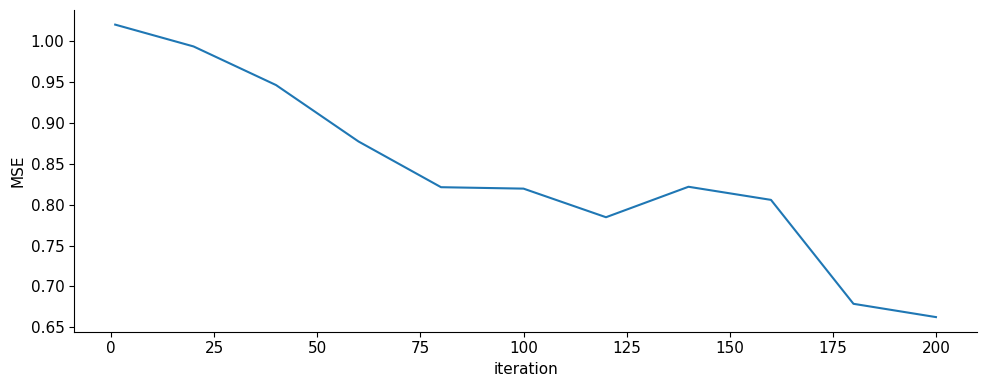

 iter     loss       sec  peak_gb
    1 1.020122  0.776099 0.956289
   20 0.993431  3.180718 0.967663
   40 0.946201  5.340644 0.967663
   60 0.877199  7.833059 0.967663
   80 0.821306 10.308859 0.967663
  100 0.819567 12.218386 0.967663
  120 0.784590 14.510185 0.967663
  140 0.821845 16.970481 0.967663
  160 0.805798 19.087015 0.967663
  180 0.678710 21.085307 0.967663
  200 0.662457 23.018211 0.967663


In [8]:
hp = pd.DataFrame(hist_pilot)
fig, ax = plt.subplots()
ax.plot(hp["iter"], hp["loss"])
ax.set_xlabel("iteration")
ax.set_ylabel("MSE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
print(hp.to_string(index=False))


## 8. Longer training

Iteration count is set from the measured pilot step time so the run stays on this 4 GB GPU (not a silent 100k-iter claim).


pilot sec/iter 0.12 -> full n_iters 4000 (cap 4000; published is 100000)
GPU VRAM 4.0 GB; using WAVENET_4GB (8x64). Official 36x256 needs ~8 GB.


C:\Users\Shivank\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


using wavenet {'num_res_layers': 8, 'res_channels': 64, 'in_channels': 8, 'label_embed_classes': 4}
full iter     1  loss 1.0201  peak 0.97 GB


full iter    50  loss 0.9219  peak 0.98 GB


full iter   100  loss 0.8196  peak 0.98 GB


...

full iter  3850  loss 0.1033  peak 0.98 GB


full iter  3900  loss 0.1063  peak 0.98 GB


full iter  3950  loss 0.1915  peak 0.98 GB


full iter  4000  loss 0.1249  peak 0.98 GB
saved C:\Users\Shivank\Videos\ECG - GenAi\synthetic_generation\checkpoints\full_4000.pt


full checkpoint C:\Users\Shivank\Videos\ECG - GenAi\synthetic_generation\checkpoints\full_last.pt
peak_gb 0.983


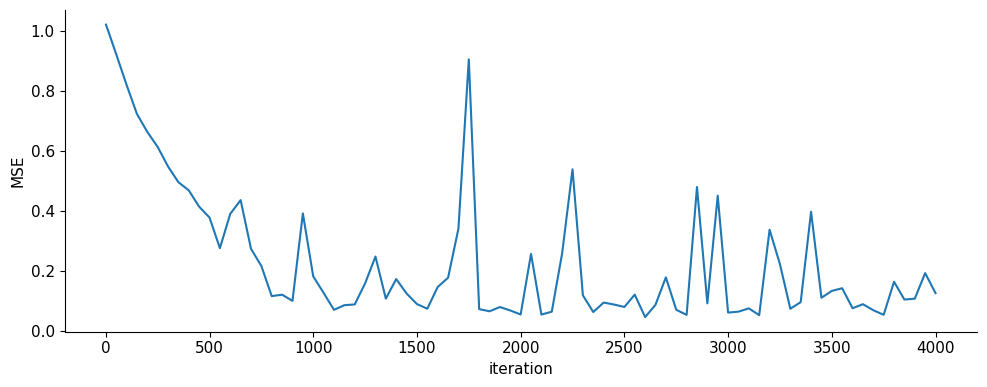

final logged loss {'iter': 4000.0, 'loss': 0.12486090511083603, 'sec': 405.1832604408264, 'peak_gb': 0.9829549789428711}


In [9]:
sec_per = hist_pilot[-1]["sec"] / max(hist_pilot[-1]["iter"], 1)
# ~50 minutes wall clock after the pilot
n_full = int(min(4000, max(400, 50 * 60 / sec_per)))
TRAIN_FULL_RUN = dict(TRAIN_FULL)
TRAIN_FULL_RUN["n_iters"] = n_full
print(f"pilot sec/iter {sec_per:.2f} -> full n_iters {n_full} (cap 4000; published is 100000)")
net, hist_full, peak_full, ckpt_full = train_loop(X_train, y_train, TRAIN_FULL_RUN, tag="full")
print("full checkpoint", ckpt_full)
print("peak_gb", round(peak_full, 3))
hf = pd.DataFrame(hist_full)
fig, ax = plt.subplots()
ax.plot(hf["iter"], hf["loss"])
ax.set_xlabel("iteration")
ax.set_ylabel("MSE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
print("final logged loss", hf.iloc[-1].to_dict())


## 9. Generate pilot synthetic pool


In [10]:
device = torch.device("cuda")
ckpt = torch.load(ckpt_full, map_location="cpu", weights_only=False)
from synthetic_generation.model import SSSD_ECG
net = SSSD_ECG(**ckpt["wavenet_config"]).to(device)
net.load_state_dict(ckpt["model_state_dict"])
net.eval()

xs, ys = [], []
for cls_name, n in PILOT_SAMPLES_PER_CLASS.items():
    cid = CLASS_ORDER.index(cls_name)
    print("sampling", cls_name, n)
    x = generate_class_batch(net, cid, n, device, batch_size=1)
    xs.append(x)
    ys.append(np.full(n, cid, dtype=np.int64))

X_syn = np.concatenate(xs, axis=0).astype(np.float32)
y_syn = np.concatenate(ys, axis=0)
print("X_syn", X_syn.shape, X_syn.dtype)
print("y_syn", y_syn.shape, np.bincount(y_syn, minlength=4))
assert X_syn.shape[1:] == (1000, 12)


sampling SR 16


sampling AFIB 32


sampling STACH 32


sampling SBRAD 48


X_syn (128, 1000, 12) float32
y_syn (128,) [16 32 32 48]


## 10. Basic sanity checks


In [11]:
san = basic_sanity(X_syn)
print(san)
keep = np.isfinite(X_syn).all(axis=(1, 2))
keep &= ~(X_syn.std(axis=1) < 1e-8).all(axis=1)
keep &= np.abs(X_syn).max(axis=(1, 2)) <= 20
print("pass_frac", float(keep.mean()))
X_syn_ok, y_syn_ok = X_syn[keep], y_syn[keep]
print("kept", X_syn_ok.shape)


{'n': 128, 'nan_inf': 0, 'flatline': 0, 'extreme_amp': 0, 'bad_shape': 0, 'fail': 0}
pass_frac 1.0
kept (128, 1000, 12)


## 11. Visual inspection


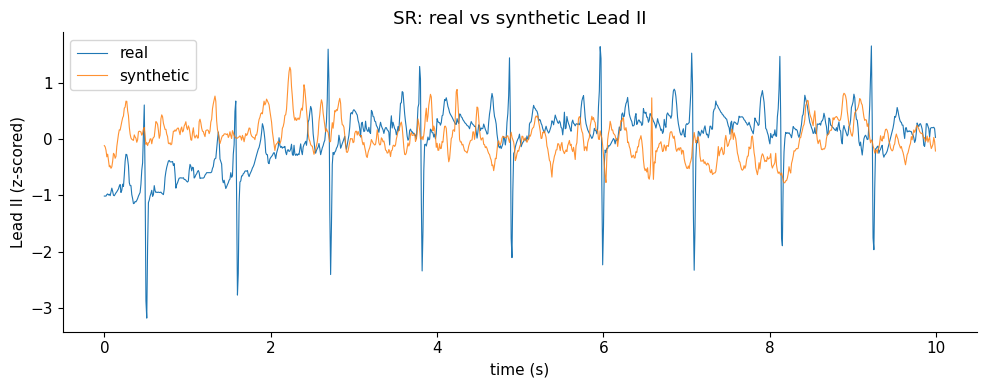

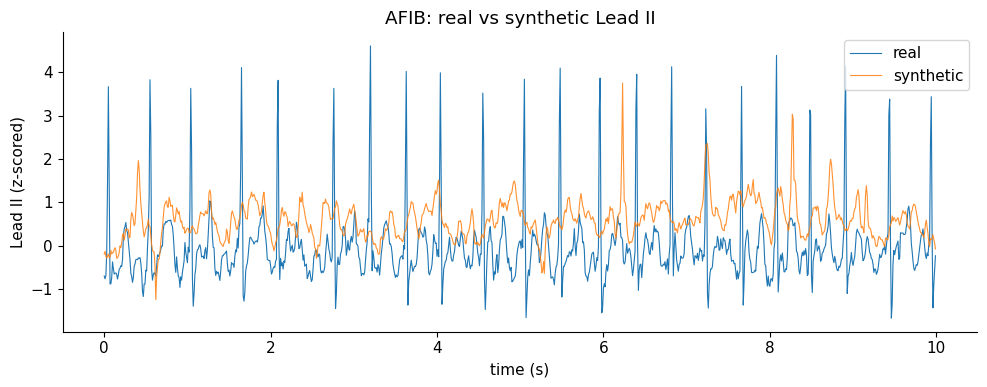

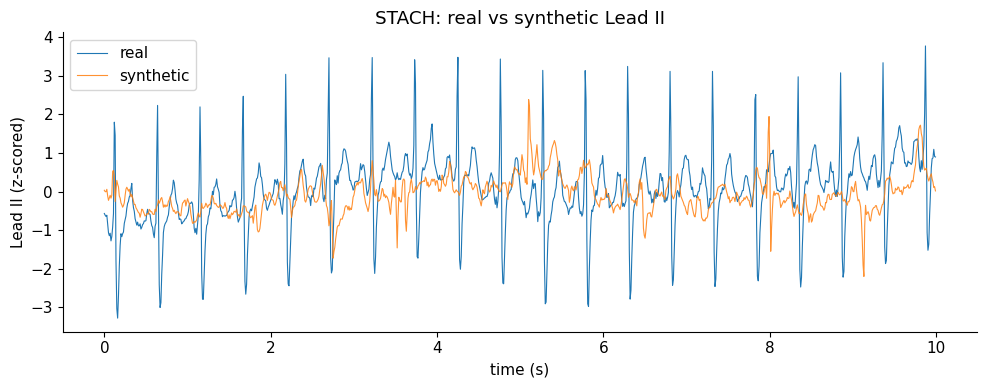

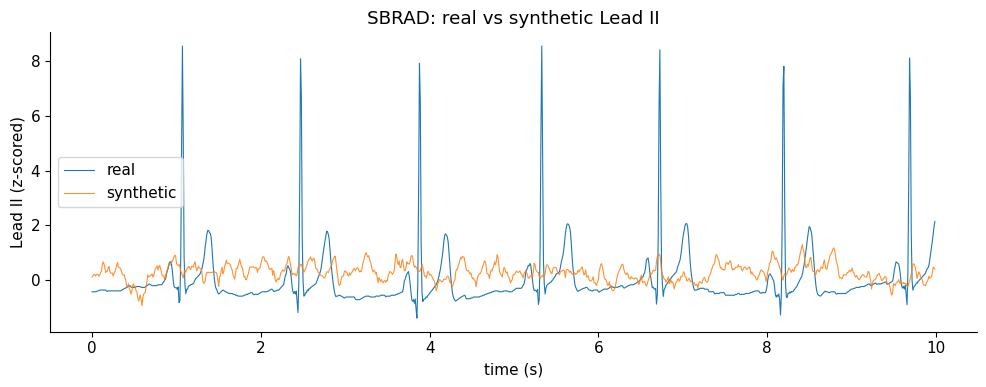

In [12]:
def plot_lead_ii(real, syn, title):
    t = np.arange(1000) / 100.0
    fig, ax = plt.subplots()
    ax.plot(t, real[:, 1], label="real", lw=0.8)
    ax.plot(t, syn[:, 1], label="synthetic", lw=0.8, alpha=0.85)
    ax.set_title(title)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("Lead II (z-scored)")
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
for c, name in enumerate(CLASS_ORDER):
    ridx = rng.choice(np.where(y_train == c)[0])
    sidx = rng.choice(np.where(y_syn_ok == c)[0]) if (y_syn_ok == c).any() else None
    if sidx is None:
        print("no synthetic", name)
        continue
    plot_lead_ii(X_train[ridx], X_syn_ok[sidx], f"{name}: real vs synthetic Lead II")


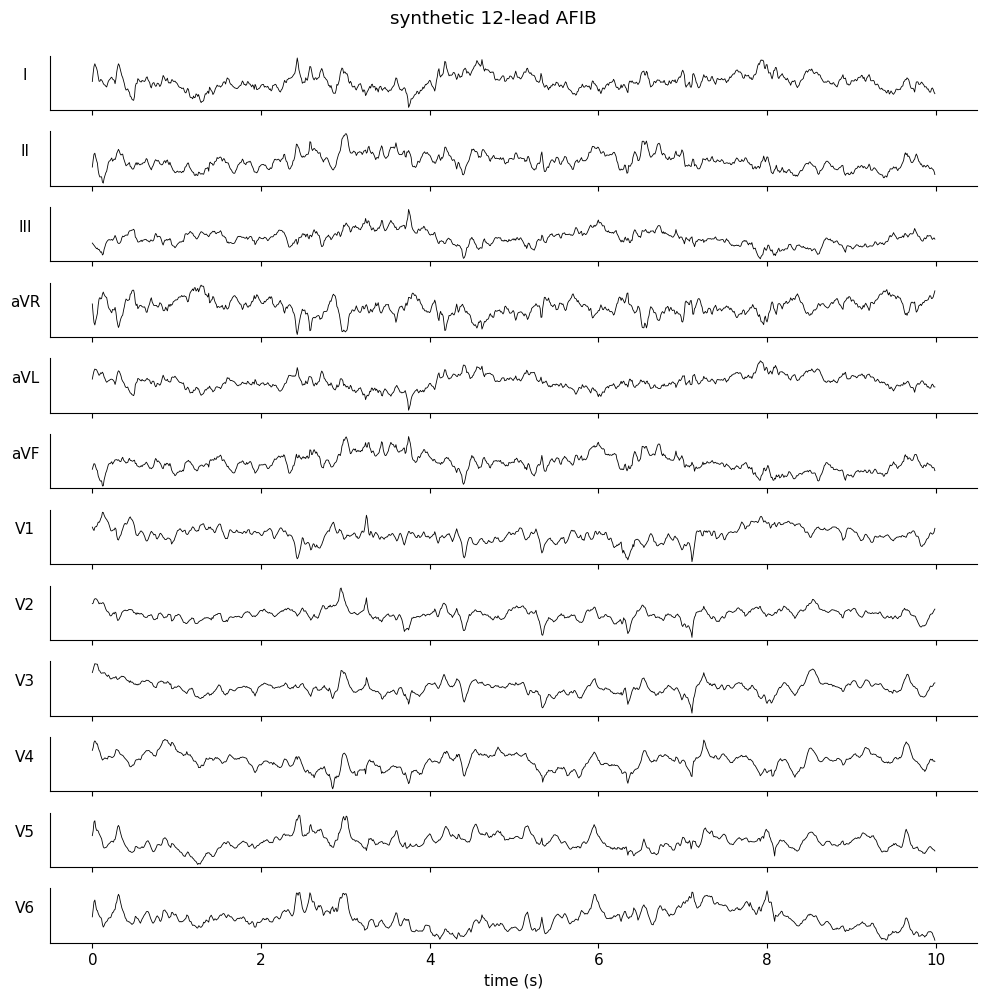

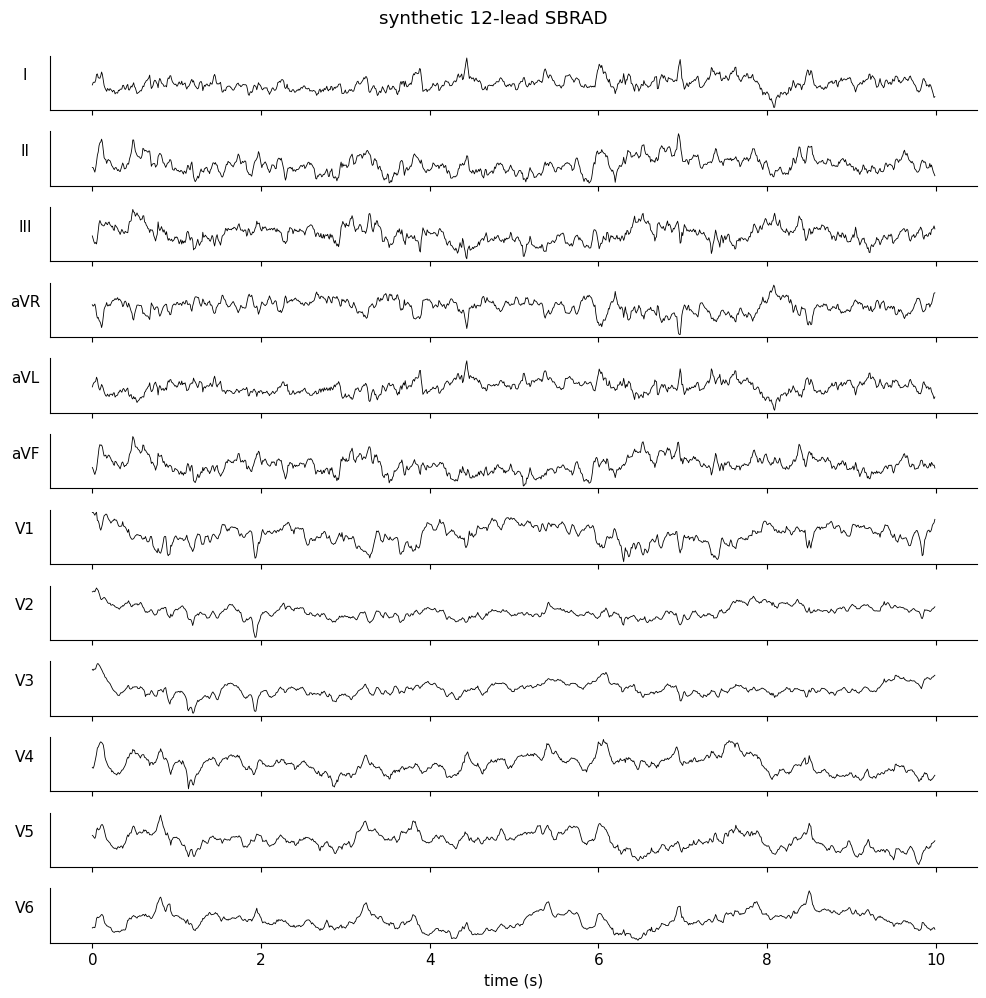

In [13]:
def plot_12(x, title):
    t = np.arange(1000) / 100.0
    fig, axes = plt.subplots(12, 1, figsize=(10, 10), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(t, x[:, i], lw=0.6, color="black")
        ax.set_ylabel(LEAD_ORDER_12[i], rotation=0, labelpad=18)
        ax.set_yticks([])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    axes[-1].set_xlabel("time (s)")
    fig.suptitle(title, y=0.995)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED + 1)
for name in ["AFIB", "SBRAD"]:
    c = CLASS_ORDER.index(name)
    sidx = rng.choice(np.where(y_syn_ok == c)[0])
    plot_12(X_syn_ok[sidx], f"synthetic 12-lead {name}")


## 12. Lightweight diversity check


In [14]:
def mean_offdiag_corr(x, n=min(24, len(x))):
    z = x[:n].reshape(n, -1)
    z = z - z.mean(axis=1, keepdims=True)
    z = z / (z.std(axis=1, keepdims=True) + 1e-8)
    c = (z @ z.T) / z.shape[1]
    iu = np.triu_indices(n, k=1)
    return float(c[iu].mean()), float(c[iu].max())

print("mean/max pairwise corr (flattened, n<=24)")
for c, name in enumerate(CLASS_ORDER):
    xs = X_syn_ok[y_syn_ok == c]
    if len(xs) < 2:
        print(name, "too few")
        continue
    mu, mx = mean_offdiag_corr(xs)
    print(f"  {name:6s} mean {mu:.3f}  max {mx:.3f}")


mean/max pairwise corr (flattened, n<=24)
  SR     mean 0.028  max 0.359
  AFIB   mean 0.526  max 0.625
  STACH  mean 0.239  max 0.383
  SBRAD  mean 0.621  max 0.708


## 13. Save


In [15]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "samples").mkdir(exist_ok=True)
np.save(OUT_DIR / "X_synthetic.npy", X_syn_ok)
np.save(OUT_DIR / "y_synthetic.npy", y_syn_ok)
meta = metadata_rows(y_syn_ok)
meta.to_csv(OUT_DIR / "metadata.csv", index=False)
np.save(ROOT / "samples" / "X_synthetic.npy", X_syn_ok)

used_w = ckpt["wavenet_config"]
config_out = {
    "generator": GENERATOR_NAME,
    "source": GENERATOR_SOURCE,
    "seed": SEED,
    "train_only": True,
    "n_train": int(len(y_train)),
    "diffusion": DIFFUSION_CONFIG,
    "wavenet_official": WAVENET_CONFIG,
    "wavenet_used": used_w,
    "train_pilot": TRAIN_PILOT,
    "train_full": TRAIN_FULL_RUN,
    "independent_leads": INDEPENDENT_LEADS,
    "lead_order_12": LEAD_ORDER_12,
    "samples_requested": PILOT_SAMPLES_PER_CLASS,
    "samples_kept": {CLASS_ORDER[i]: int((y_syn_ok == i).sum()) for i in range(4)},
    "sanity": san,
    "peak_gb_pilot": peak_pilot,
    "peak_gb_full": peak_full,
    "checkpoint": str(ckpt_full).replace("\\", "/"),
}
(ROOT / "config.json").write_text(json.dumps(config_out, indent=2), encoding="utf-8")
print("wrote", OUT_DIR)
print("files", sorted(p.name for p in OUT_DIR.iterdir()))
print("gen files", sorted(p.name for p in ROOT.iterdir() if p.is_file()))


wrote C:\Users\Shivank\Videos\ECG - GenAi\synthetic_data
files ['X_synthetic.npy', 'metadata.csv', 'y_synthetic.npy']
gen files ['__init__.py', 'config.json', 'config.py', 'data.py', 'history.json', 'leads.py', 'model.py', 's4.py', 'sample.py', 'train.py', 'utils.py']


## Week 4 outcome

1. Generator: adapted SSSD-ECG (official architecture + 4-class conditioning + I/II/V1–V6 reconstruction).
2. Training: from scratch on X_train/y_train only (see cells above for whether it succeeded).
3. Per-class counts: see `synthetic_data/metadata.csv` / config.json.
4. Sanity pass rate: printed in section 10.
5. Structure: visual comparison only — no quality claim.
6. Failure modes: see observations after plots.
7. Ready for Week 5 quality assessment if files exist and sanity fail count is reported.

**GENERATED SYNTHETIC ECG POOL READY FOR QUALITY ASSESSMENT.**
